**Low-Light Image Enhancement Using Traditional Image Processing Techniques**

**ARTI 403 – Image Processing | Group 6**

**Group members:** Juri Sulayhim, Layan Mohammed AlHarthi, Raneem Abdulkarim Albassami, Haneen Alsaflan, Danyah Khan (Team Leader), Reema Alshahrani.

**Dataset:** LOL (485 training pairs and 15 test pairs) — "https://drive.google.com/file/d/157bjO1_cFuSd0HWDUuAmcHRJDVyWpOxB/view"

**Input File:** /content/LOLdataset.zip (upload through the Colab Files panel).



**1. Import libraries**


In [1]:
%pip install opencv-python scikit-image pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

# Part 1 - Image Loading and RGB-to-Lab Conversion
from pathlib import Path
import random
import zipfile

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

OpenCV version: 4.8.1
NumPy version: 1.26.4


**2. Extract the LOL dataset**

In [3]:
from pathlib import Path
import zipfile

# Dataset file and extraction folder
ZIP_PATH = Path.home() / "Downloads" / "LOLdataset.zip"
EXTRACT_DIR = Path.home() / "Downloads" / "LOL"
EXTRACTION_MARKER = EXTRACT_DIR / ".extraction_complete"

# Check the ZIP file
if not ZIP_PATH.is_file():
    raise FileNotFoundError(
        "Upload LOLdataset.zip to Colab Files, then rerun this cell."
    )
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f"This is not a valid ZIP file: {ZIP_PATH}")

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Extract the images
if not EXTRACTION_MARKER.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(EXTRACT_DIR)
    EXTRACTION_MARKER.touch()
    print("Dataset extracted to:", EXTRACT_DIR)
else:
    print("Using the dataset already extracted at:", EXTRACT_DIR)

# Display extracted folders
for folder in sorted(p for p in EXTRACT_DIR.iterdir() if p.is_dir()):
    print("Top-level folder:", folder.name)


FileNotFoundError: Upload LOLdataset.zip to Colab Files, then rerun this cell.

**3. Check dataset folders**

In [ ]:
# Locate training and test folders
candidates = [
    p.parent for p in EXTRACT_DIR.rglob("eval15")
    if p.is_dir()
    and (p.parent / "our485").is_dir()
    and "__MACOSX" not in p.parts]

if len(candidates) != 1:
    raise RuntimeError( f"Expected one LOL-v1 dataset folder, found {len(candidates)}: {candidates}")

DATASET_ROOT = candidates[0]
TRAIN_LOW_DIR = DATASET_ROOT / "our485" / "low"
TRAIN_HIGH_DIR = DATASET_ROOT / "our485" / "high"
TEST_LOW_DIR = DATASET_ROOT / "eval15" / "low"
TEST_HIGH_DIR = DATASET_ROOT / "eval15" / "high"

# Check the number of PNG images
folders = [("Train low", TRAIN_LOW_DIR, 485),
    ("Train ground truth", TRAIN_HIGH_DIR, 485),
    ("Test low", TEST_LOW_DIR, 15),
    ("Test ground truth", TEST_HIGH_DIR, 15),]

for label, folder, expected in folders:
    if not folder.is_dir():
        raise FileNotFoundError(f"Required folder is missing: {folder}")

    count = len(list(folder.glob("*.png")))
    print(f"{label}: {count} PNG images (expected {expected})")

    if count != expected:
        raise ValueError(f"Unexpected image count in {folder}")

print("All LOL dataset folders verified successfully.")

Train low: 485 PNG images (expected 485)
Train ground truth: 485 PNG images (expected 485)
Test low: 15 PNG images (expected 15)
Test ground truth: 15 PNG images (expected 15)
All LOL dataset folders verified successfully.


**4. Load images and convert RGB to Lab**

In [ ]:
# Read images in RGB format
def read_rgb(path):
    """Read one PNG as an RGB uint8 array (height, width, 3)."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise IOError(f"Could not load image: {path}")

    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def filename_sort_key(name):
    """Put 2.png before 10.png for the dataset's numbered filenames."""
    return (len(name), name)


# Match low-light and normal-light images by filename
def load_image_pairs(low_dir, high_dir, filenames=None):
    """Load low/high image pairs by matching filenames; return Lab-ready data."""
    low_files = {p.name: p for p in Path(low_dir).glob("*.png")}
    high_files = {p.name: p for p in Path(high_dir).glob("*.png")}

    if not low_files or not high_files:
        raise ValueError("No PNG images were found in one or both folders.")

    missing_gt = sorted(set(low_files) - set(high_files))
    missing_low = sorted(set(high_files) - set(low_files))
    if missing_gt or missing_low:
        raise ValueError(
            f"Unmatched image names. Missing ground truth: {missing_gt}; "
            f"missing low-light images: {missing_low}"
        )

    if filenames is None:
        filenames = sorted(low_files, key=filename_sort_key)

    pairs = []
    for name in filenames:
        if name not in low_files:
            raise FileNotFoundError(f"Requested image not found: {name}")

        # Load the image pair
        low_rgb = read_rgb(low_files[name])
        gt_rgb = read_rgb(high_files[name])

        if low_rgb.shape != gt_rgb.shape:
            raise ValueError( f"Dimension mismatch for {name}: {low_rgb.shape} vs {gt_rgb.shape}" )

        # Convert low-light RGB images to Lab
        low_lab = cv2.cvtColor(low_rgb, cv2.COLOR_RGB2LAB)
        L, a, b = cv2.split(low_lab)

        # Keep the original image data for later use
        pair = {"filename": name,
            "low_rgb": low_rgb,
            "low_lab": low_lab,
            "L": L,
            "a": a,
            "b": b,
            "gt_rgb": gt_rgb,}

        for key in ("low_rgb", "low_lab", "L", "a", "b", "gt_rgb"):
            pair[key].flags.writeable = False

        pairs.append(pair)

    return pairs


# Reconstruct RGB from Lab channels
def reconstruct_rgb(L_new, a, b):
    """Combine a new L channel with original a/b and convert Lab back to RGB."""
    for name, channel in (("L_new", L_new), ("a", a), ("b", b)):
        if not isinstance(channel, np.ndarray) or channel.dtype != np.uint8:
            raise TypeError(f"{name} must be a uint8 NumPy array.")

    if L_new.ndim != 2 or L_new.shape != a.shape or L_new.shape != b.shape:
        raise ValueError("L, a and b must be 2D arrays of matching dimensions.")

    lab = cv2.merge((L_new, a, b))
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


print("Functions ready: read_rgb, load_image_pairs, reconstruct_rgb")

Functions ready: read_rgb, load_image_pairs, reconstruct_rgb


**5. Load test images**

In [ ]:
# Load the 15 test image pairs
test_pairs = load_image_pairs(TEST_LOW_DIR, TEST_HIGH_DIR)
assert len(test_pairs) == 15, "The standard test split must contain 15 pairs."

print("Test pairs loaded:", len(test_pairs))
print("Test filenames:", [pair["filename"] for pair in test_pairs])

Test pairs loaded: 15
Test filenames: ['1.png', '22.png', '23.png', '55.png', '79.png', '111.png', '146.png', '179.png', '493.png', '547.png', '665.png', '669.png', '748.png', '778.png', '780.png']


**6. Select training images**

In [ ]:
# Training subset settings
USE_TRAIN_SUBSET = True
TRAIN_SUBSET_SIZE = 20
RANDOM_SEED = 42

train_pairs = []

if USE_TRAIN_SUBSET:

    # Choose images from the training set
    all_train_names = sorted((p.name for p in TRAIN_LOW_DIR.glob("*.png")),
        key=filename_sort_key,)
    if not (1 <= TRAIN_SUBSET_SIZE <= len(all_train_names)):
        raise ValueError("TRAIN_SUBSET_SIZE is outside the available training images.")

    rng = random.Random(RANDOM_SEED)
    selected_names = sorted(rng.sample(all_train_names, TRAIN_SUBSET_SIZE),
        key=filename_sort_key, )

    # Load the selected training pairs
    train_pairs = load_image_pairs(TRAIN_LOW_DIR, TRAIN_HIGH_DIR, filenames=selected_names)

assert TRAIN_LOW_DIR.resolve() != TEST_LOW_DIR.resolve()

print("Training pairs loaded for tuning:", len(train_pairs))
print("Selected training filenames:", [p["filename"] for p in train_pairs])

Training pairs loaded for tuning: 20
Selected training filenames: ['21.png', '26.png', '27.png', '64.png', '69.png', '76.png', '82.png', '98.png', '142.png', '145.png', '167.png', '189.png', '474.png', '549.png', '572.png', '605.png', '626.png', '664.png', '667.png', '757.png']


**7. Check loaded images and conversion**


In [ ]:
# Check image types and dimensions
def verify_pairs(pairs, set_name):
    """Check dtypes, shapes, and the basic RGB -> Lab -> RGB round trip."""
    print(f"--- Checking {set_name}: {len(pairs)} pairs ---")

    mean_errors = []
    for pair in pairs:
        low_rgb = pair["low_rgb"]
        gt_rgb = pair["gt_rgb"]
        L, a, b = pair["L"], pair["a"], pair["b"]

        assert low_rgb.dtype == gt_rgb.dtype == np.uint8
        assert low_rgb.shape == gt_rgb.shape
        assert low_rgb.ndim == 3 and low_rgb.shape[2] == 3
        assert L.shape == a.shape == b.shape == low_rgb.shape[:2]
        assert all(ch.dtype == np.uint8 for ch in (L, a, b))

        # Compare original and reconstructed images
        reconstructed = reconstruct_rgb(L, a, b)
        difference = np.abs(reconstructed.astype(np.int16) - low_rgb.astype(np.int16))
        mean_errors.append(float(difference.mean()))

        print(f"{pair['filename']}: size={low_rgb.shape}, "
            f"mean round-trip difference={difference.mean():.3f}")

    print(f"Average round-trip difference: {np.mean(mean_errors):.3f}")
    print("Datatype and dimension checks passed.\n")


verify_pairs(test_pairs, "test set")
if train_pairs:
    verify_pairs(train_pairs, "training subset")

--- Checking test set: 15 pairs ---
1.png: size=(400, 600, 3), mean round-trip difference=0.864
22.png: size=(400, 600, 3), mean round-trip difference=0.720
23.png: size=(400, 600, 3), mean round-trip difference=0.890
55.png: size=(400, 600, 3), mean round-trip difference=0.892
79.png: size=(400, 600, 3), mean round-trip difference=0.736
111.png: size=(400, 600, 3), mean round-trip difference=0.766
146.png: size=(400, 600, 3), mean round-trip difference=0.628
179.png: size=(400, 600, 3), mean round-trip difference=0.704
493.png: size=(400, 600, 3), mean round-trip difference=0.860
547.png: size=(400, 600, 3), mean round-trip difference=0.870
665.png: size=(400, 600, 3), mean round-trip difference=1.033
669.png: size=(400, 600, 3), mean round-trip difference=0.838
748.png: size=(400, 600, 3), mean round-trip difference=1.007
778.png: size=(400, 600, 3), mean round-trip difference=0.875
780.png: size=(400, 600, 3), mean round-trip difference=0.957
Average round-trip difference: 0.843
Dat

**8. Implement Histogram Equalization** 

In [ ]:
def apply_histogram_equalization(L):
    """
    Apply Histogram Equalization to the Lab lightness channel.

    Parameters:
        L: Lightness channel (uint8, 0-255)

    Returns:
        Enhanced lightness channel
    """

    enhanced_L = cv2.equalizeHist(L)

    return enhanced_L

**9. Tesing it on one image**

Original L shape: (400, 600)
Enhanced L shape: (400, 600)
Enhanced L data type: uint8
Minimum intensity: 0
Maximum intensity: 255


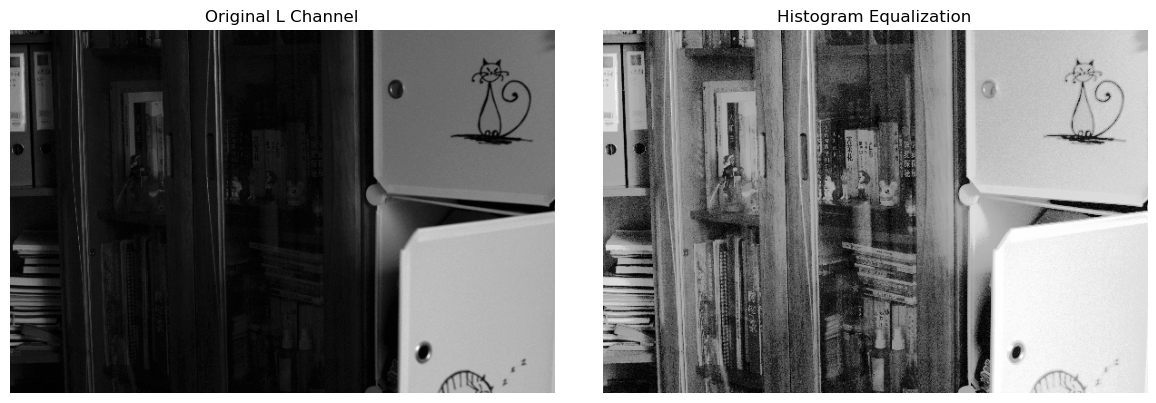

In [ ]:
# Select one image pair
pair = test_pairs[0]  # Change the index to select a different image pair (0-14)

# Apply Histogram Equalization
he_L = apply_histogram_equalization(pair["L"])

print("Original L shape:", pair["L"].shape)
print("Enhanced L shape:", he_L.shape)
print("Enhanced L data type:", he_L.dtype)
print("Minimum intensity:", he_L.min())
print("Maximum intensity:", he_L.max())

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(pair["L"], cmap="gray")
plt.title("Original L Channel")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(he_L, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()

HE improves visibility, but it may also amplify noise and over-enhance bright regions.

**10. Reconstruct the enhanced RGB image**

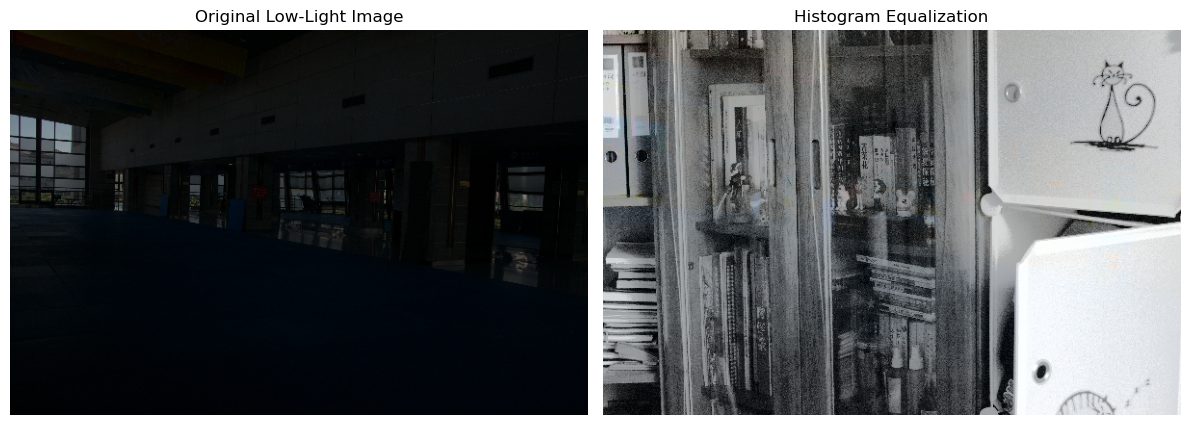

In [ ]:
# def reconstruct_rgb(enhanced_L, a, b):
#     lab_image = cv2.merge((enhanced_L, a, b))
#     rgb_image = cv2.cvtColor(lab_image, cv2.COLOR_LAB2RGB)
#     return rgb_image

# Reconstruct enhanced RGB image
he_rgb = reconstruct_rgb(
    he_L,
    pair["a"],
    pair["b"]
)

# Display original and enhanced images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(pair["low_rgb"])
plt.title("Original Low-Light Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(he_rgb)
plt.title("Histogram Equalization")
plt.axis("off")

plt.tight_layout()
plt.show()

## Histogram Equalization (HE) – Observations

- **Brightness:** Dark areas became more visible after applying Histogram Equalization.
- **Contrast:** Details in the bookshelf and surrounding objects became clearer.
- **Noise and Over-enhancement:** The enhanced image shows noticeable noise, while some bright areas appear overexposed.

**Overall:** Histogram Equalization improves image visibility and global contrast, but it can also amplify noise and over-enhance bright regions.

**11. Apply HE to all 15 test images**

In [ ]:
# Apply Histogram Equalization to all test images
he_results = []

for pair in test_pairs:

    # Apply HE to the L channel
    enhanced_L = apply_histogram_equalization(pair["L"])

    # Reconstruct RGB image
    enhanced_rgb = reconstruct_rgb(
        enhanced_L,
        pair["a"],
        pair["b"]
    )

    he_results.append({
        "filename": pair["filename"],
        "enhanced_L": enhanced_L,
        "enhanced_rgb": enhanced_rgb,
        "gt_rgb": pair["gt_rgb"]
    })

print("Number of processed images:", len(he_results))

Number of processed images: 15


**12. Save the enhanced images**

In [ ]:
HE_OUTPUT_DIR = EXTRACT_DIR / "HE_Results"
HE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for result in he_results:

    filename = result["filename"]

    output_path = HE_OUTPUT_DIR / filename

    # Convert RGB to BGR before saving with OpenCV
    image_bgr = cv2.cvtColor(
        result["enhanced_rgb"],
        cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(str(output_path), image_bgr)

print("HE images saved to:", HE_OUTPUT_DIR)

#verify saved images
saved_images = list(HE_OUTPUT_DIR.glob("*.png"))

print("Number of saved images:", len(saved_images))
print("First saved image:", saved_images[0].name)

HE images saved to: C:\Users\Saudi Gamerz\Downloads\LOL\HE_Results
Number of saved images: 15
First saved image: 1.png


## CLAHE Implementation and Parameter Tuning

**13. CLAHE implementation**

In [ ]:
def apply_clahe(L, clip_limit, tile_grid):
    """
    Apply CLAHE to the Lab lightness channel.
    """
    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid
    )
    return clahe.apply(L)


print("CLAHE function ready.")


**14. CLAHE parameter tuning using training images only**

In [ ]:

candidate_clip_limits = [1.0, 2.0, 3.0, 4.0]
candidate_tile_grids = [(4, 4), (8, 8), (16, 16)]

clahe_tuning_rows = []

for clip in candidate_clip_limits:
    for tile in candidate_tile_grids:

        psnr_list = []
        ssim_list = []

        for pair in train_pairs:

            enhanced_L = apply_clahe(
                pair["L"], clip, tile
            )

            enhanced_rgb = reconstruct_rgb(
                enhanced_L, pair["a"], pair["b"]
            )

            p, s = evaluate_image(
                enhanced_rgb, pair["gt_rgb"]
            )

            psnr_list.append(p)
            ssim_list.append(s)

        clahe_tuning_rows.append({
            "Clip Limit": clip,
            "Tile Grid": str(tile),
            "PSNR Mean": np.mean(psnr_list),
            "SSIM Mean": np.mean(ssim_list)
        })

df_clahe_tuning = pd.DataFrame(clahe_tuning_rows)

print(df_clahe_tuning.round(4).to_string(index=False))

# Select the parameters with the highest mean SSIM
best_row = df_clahe_tuning.loc[
    df_clahe_tuning["SSIM Mean"].idxmax()
]

BEST_CLAHE_CLIP = float(best_row["Clip Limit"])
BEST_CLAHE_TILE = eval(best_row["Tile Grid"])

print("\nBest CLAHE clip limit:", BEST_CLAHE_CLIP)
print("Best CLAHE tile grid:", BEST_CLAHE_TILE)


**15. Apply the best CLAHE parameters to the 15 test images**

In [ ]:
clahe_results = []

for pair in test_pairs:

    enhanced_L = apply_clahe(
        pair["L"],
        BEST_CLAHE_CLIP,
        BEST_CLAHE_TILE
    )

    enhanced_rgb = reconstruct_rgb(
        enhanced_L,
        pair["a"],
        pair["b"]
    )

    clahe_results.append({
        "filename": pair["filename"],
        "enhanced_L": enhanced_L,
        "enhanced_rgb": enhanced_rgb,
        "gt_rgb": pair["gt_rgb"]
    })

print("CLAHE processed:", len(clahe_results), "images")

# Add CLAHE to the comparison results
add_method("CLAHE", clahe_results)

## Quantitative Evaluation — PSNR and SSIM

**16. Import libraries and define metrics**

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity


def evaluate_image(enhanced_rgb, gt_rgb):
    """Calculate PSNR and SSIM against the normal-light reference."""

    if enhanced_rgb.shape != gt_rgb.shape:
        raise ValueError("Image dimensions do not match.")

    if enhanced_rgb.dtype != np.uint8 or gt_rgb.dtype != np.uint8:
        raise ValueError("Images must be uint8.")

    if enhanced_rgb.ndim != 3 or enhanced_rgb.shape[2] != 3:
        raise ValueError("Expected an RGB image with 3 channels.")

    psnr_value = peak_signal_noise_ratio(
        gt_rgb, enhanced_rgb, data_range=255
    )

    ssim_value = structural_similarity(
        gt_rgb, enhanced_rgb,
        data_range=255,
        channel_axis=2
    )

    return float(psnr_value), float(ssim_value)


print("PSNR and SSIM functions ready.")


PSNR and SSIM functions ready.


**17. Collect the enhancement results**

In [ ]:

# Match test images and ground truths by filename.
test_data = {
    pair["filename"]: pair
    for pair in test_pairs
}

if len(test_pairs) != 15 or len(test_data) != 15:
    raise ValueError("Expected 15 unique test image pairs.")


def add_method(method_name, method_results):
    """Store enhanced RGB images using their filenames."""

    images = {}

    for result in method_results:
        filename = result["filename"]

        if filename in images:
            raise ValueError(f"Duplicate filename: {filename}")

        images[filename] = result["enhanced_rgb"]

    if set(images.keys()) != set(test_data.keys()):
        raise ValueError(
            f"{method_name}: Images do not match the test dataset."
        )

    results[method_name] = images


# Include the original low-light images as the baseline.
results = {
    "Low-light (Baseline)": {
        name: pair["low_rgb"]
        for name, pair in test_data.items()
    }
}

# Add the completed Histogram Equalization results.
add_method("HE", he_results)

# Add other methods when their results become available.
# add_method("CLAHE", clahe_results)
# add_method("Gamma Correction", gamma_results)
# add_method("Gamma + CLAHE", hybrid_results)

print("Methods ready for evaluation:", list(results.keys()))


Methods ready for evaluation: ['Low-light (Baseline)', 'HE']


**18. Calculate PSNR and SSIM for all 15 images**

In [ ]:

# Evaluate every method on the same 15 test images.
evaluation_rows = []

for method_name, images in results.items():

    for filename in test_data:
        enhanced_rgb = images[filename]
        gt_rgb = test_data[filename]["gt_rgb"]

        psnr_value, ssim_value = evaluate_image(
            enhanced_rgb, gt_rgb
        )

        evaluation_rows.append({
            "Method": method_name,
            "Image": filename,
            "PSNR (dB)": psnr_value,
            "SSIM": ssim_value
        })

df_per_image = pd.DataFrame(evaluation_rows)

print("Per-image evaluation results:")
print(df_per_image.round(4).to_string(index=False))


Per-image evaluation results:
              Method   Image  PSNR (dB)   SSIM
Low-light (Baseline)   1.png     7.2193 0.2309
Low-light (Baseline)  22.png     6.1071 0.1838
Low-light (Baseline)  23.png     4.6465 0.0775
Low-light (Baseline)  55.png     4.5212 0.0770
Low-light (Baseline)  79.png     5.0899 0.1974
Low-light (Baseline) 111.png     5.6122 0.1873
Low-light (Baseline) 146.png     6.6295 0.2599
Low-light (Baseline) 179.png    12.3772 0.4297
Low-light (Baseline) 493.png    10.8915 0.1966
Low-light (Baseline) 547.png     8.9776 0.2110
Low-light (Baseline) 665.png     6.8168 0.0777
Low-light (Baseline) 669.png     6.7474 0.1846
Low-light (Baseline) 748.png     9.9620 0.1845
Low-light (Baseline) 778.png     8.8772 0.0777
Low-light (Baseline) 780.png    12.1243 0.2955
                  HE   1.png    18.1309 0.6170
                  HE  22.png    19.2077 0.5710
                  HE  23.png    16.3770 0.4014
                  HE  55.png    15.6527 0.4764
                  HE  79.png  

**19. Create the final comparison table**

In [ ]:

# Calculate the mean and standard deviation of each metric.
summary = (
    df_per_image
    .groupby("Method", sort=False)[["PSNR (dB)", "SSIM"]]
    .agg(["mean", "std"])
)

summary.columns = [
    "PSNR Mean (dB)",
    "PSNR Std",
    "SSIM Mean",
    "SSIM Std"
]

# Compare each method with the original low-light baseline.
baseline = summary.loc["Low-light (Baseline)"]

summary["PSNR Improvement (dB)"] = (
    summary["PSNR Mean (dB)"] - baseline["PSNR Mean (dB)"]
)

summary["SSIM Improvement"] = (
    summary["SSIM Mean"] - baseline["SSIM Mean"]
)

print("Average results over 15 test images:")
print(summary.round(4).to_string())

# Identify the best evaluated method.
best_psnr = summary["PSNR Mean (dB)"].idxmax()
best_ssim = summary["SSIM Mean"].idxmax()

print("\nHighest average PSNR:", best_psnr)
print("Highest average SSIM:", best_ssim)


Average results over 15 test images:
                      PSNR Mean (dB)  PSNR Std  SSIM Mean  SSIM Std  PSNR Improvement (dB)  SSIM Improvement
Method                                                                                                      
Low-light (Baseline)          7.7733    2.6172     0.1914    0.0950                 0.0000            0.0000
HE                           14.2553    2.9174     0.4247    0.1037                 6.4819            0.2333

Highest average PSNR: HE
Highest average SSIM: HE


**20. Create a per-image comparison table**

In [ ]:

# Arrange all methods side by side for each test image.
per_image_table = df_per_image.pivot(
    index="Image",
    columns="Method",
    values=["PSNR (dB)", "SSIM"]
)

# Preserve the original test image order.
image_order = list(test_data.keys())
per_image_table = per_image_table.loc[image_order]

# Preserve the method order.
per_image_table = per_image_table.reindex(
    columns=list(results.keys()),
    level=1
)

print("PSNR and SSIM comparison for each image:")
print(per_image_table.round(4).to_string())


PSNR and SSIM comparison for each image:
                   PSNR (dB)                          SSIM        
Method  Low-light (Baseline)       HE Low-light (Baseline)      HE
Image                                                             
1.png                 7.2193  18.1309               0.2309  0.6170
22.png                6.1071  19.2077               0.1838  0.5710
23.png                4.6465  16.3770               0.0775  0.4014
55.png                4.5212  15.6527               0.0770  0.4764
79.png                5.0899  14.8278               0.1974  0.5180
111.png               5.6122  15.6400               0.1873  0.4706
146.png               6.6295  15.1419               0.2599  0.4287
179.png              12.3772   9.4768               0.4297  0.2694
493.png              10.8915  10.0585               0.1966  0.3261
547.png               8.9776  14.6672               0.2110  0.4334
665.png               6.8168  14.3782               0.0777  0.3146
669.png              

**21. Save the results**

In [ ]:

# Save the evaluation tables as CSV files.
OUTPUT_DIR = Path("evaluation_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_per_image.round(4).to_csv(
    OUTPUT_DIR / "metrics_per_image.csv",
    index=False
)

per_image_table.round(4).to_csv(
    OUTPUT_DIR / "metrics_comparison.csv"
)

summary.round(4).to_csv(
    OUTPUT_DIR / "metrics_summary.csv"
)

print("Results saved in:", OUTPUT_DIR.resolve())


Results saved in: C:\Users\layan\Downloads\evaluation_results


CELL A: Gamma Correction function

In [ ]:
def apply_gamma_correction(L, gamma):
    """
    Apply Gamma Correction to the Lab lightness channel.

    Parameters:
        L: Lightness channel (uint8, 0-255)
        gamma: gamma value (gamma < 1 brightens dark regions)

    Returns:
        Enhanced lightness channel (uint8)
    """
    # Build a lookup table: output = 255 * (input / 255) ** gamma
    table = np.array([255.0 * (i / 255.0) ** gamma for i in range(256)])
    table = np.clip(table, 0, 255).astype(np.uint8)
    return cv2.LUT(L, table)

CELL B: Tune gamma on the TRAINING subset only

In [ ]:
candidate_gammas = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

tuning_rows = []
for g in candidate_gammas:
    psnr_list, ssim_list = [], []
    for pair in train_pairs:
        enhanced_L = apply_gamma_correction(pair["L"], g)
        enhanced_rgb = reconstruct_rgb(enhanced_L, pair["a"], pair["b"])
        p, s = evaluate_image(enhanced_rgb, pair["gt_rgb"])
        psnr_list.append(p)
        ssim_list.append(s)
    tuning_rows.append({
        "Gamma": g,
        "PSNR Mean (dB)": np.mean(psnr_list),
        "SSIM Mean": np.mean(ssim_list),
    })

df_gamma_tuning = pd.DataFrame(tuning_rows)
print(df_gamma_tuning.round(4).to_string(index=False))

# Selection criterion: highest mean SSIM on the training subset.
# (State the criterion you choose in the paper.)
BEST_GAMMA = float(df_gamma_tuning.loc[df_gamma_tuning["SSIM Mean"].idxmax(), "Gamma"])
print("\nSelected gamma:", BEST_GAMMA)

 Gamma  PSNR Mean (dB)  SSIM Mean
   0.3         15.1038     0.6826
   0.4         11.8306     0.6138
   0.5          9.9570     0.5204
   0.6          8.8091     0.4248
   0.7          8.0451     0.3371
   0.8          7.5036     0.2642
   0.9          7.0978     0.2032

Selected gamma: 0.3


CELL C: Apply Gamma Correction to the 15 test images

In [ ]:
gamma_results = []

for pair in test_pairs:
    enhanced_L = apply_gamma_correction(pair["L"], BEST_GAMMA)
    enhanced_rgb = reconstruct_rgb(enhanced_L, pair["a"], pair["b"])

    gamma_results.append({
        "filename": pair["filename"],
        "enhanced_L": enhanced_L,
        "enhanced_rgb": enhanced_rgb,
        "gt_rgb": pair["gt_rgb"],
    })

add_method("Gamma Correction", gamma_results)
print("Gamma Correction processed:", len(gamma_results), "images")


# ---------- CELL D: Hybrid pipeline (Gamma -> CLAHE) ----------
# NOTE: use the tuned CLAHE values from the teammate responsible for CLAHE.
CLAHE_CLIP_LIMIT = 2.0        # placeholder - replace with the tuned value
CLAHE_TILE_GRID = (8, 8)      # placeholder - replace with the tuned value


def apply_hybrid(L, gamma, clip_limit, tile_grid):
    """Gamma Correction first (global brightness), then CLAHE (local contrast)."""
    gamma_L = apply_gamma_correction(L, gamma)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    return clahe.apply(gamma_L)


hybrid_results = []

for pair in test_pairs:
    enhanced_L = apply_hybrid(pair["L"], BEST_GAMMA, CLAHE_CLIP_LIMIT, CLAHE_TILE_GRID)
    enhanced_rgb = reconstruct_rgb(enhanced_L, pair["a"], pair["b"])

    hybrid_results.append({
        "filename": pair["filename"],
        "enhanced_L": enhanced_L,
        "enhanced_rgb": enhanced_rgb,
        "gt_rgb": pair["gt_rgb"],
    })

add_method("Gamma + CLAHE", hybrid_results)
print("Hybrid processed:", len(hybrid_results), "images")


Gamma Correction processed: 15 images
Hybrid processed: 15 images


CELL D: Hybrid pipeline (Gamma -> CLAHE)

In [ ]:
CLAHE_CLIP_LIMIT = BEST_CLAHE_CLIP
CLAHE_TILE_GRID = BEST_CLAHE_TILE


def apply_hybrid(L, gamma, clip_limit, tile_grid):
    """Gamma Correction first (global brightness), then CLAHE (local contrast)."""
    gamma_L = apply_gamma_correction(L, gamma)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    return clahe.apply(gamma_L)


hybrid_results = []

for pair in test_pairs:
    enhanced_L = apply_hybrid(pair["L"], BEST_GAMMA, CLAHE_CLIP_LIMIT, CLAHE_TILE_GRID)
    enhanced_rgb = reconstruct_rgb(enhanced_L, pair["a"], pair["b"])

    hybrid_results.append({
        "filename": pair["filename"],
        "enhanced_L": enhanced_L,
        "enhanced_rgb": enhanced_rgb,
        "gt_rgb": pair["gt_rgb"],
    })

add_method("Gamma + CLAHE", hybrid_results)
print("Hybrid processed:", len(hybrid_results), "images")

# Then re-run the evaluation cells (PSNR/SSIM, summary tables, save CSVs)
# so the new methods appear in the comparison table.